In [2]:
%matplotlib widget
import matplotlib.pyplot as plt

import gitt_parametrization
import ici_parametrization

Loading data:   0%|          | 0/27 [00:00<?, ?it/s]

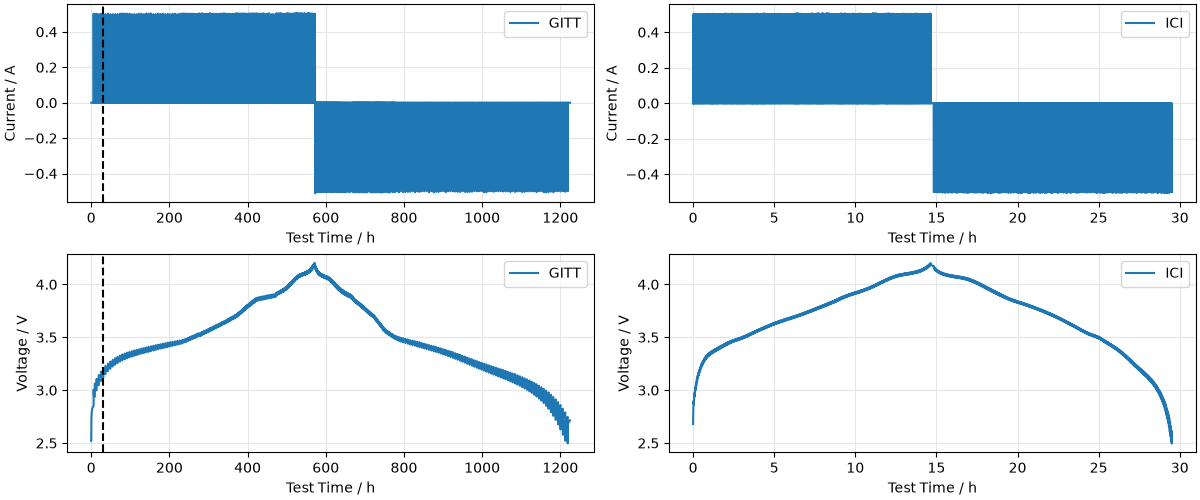

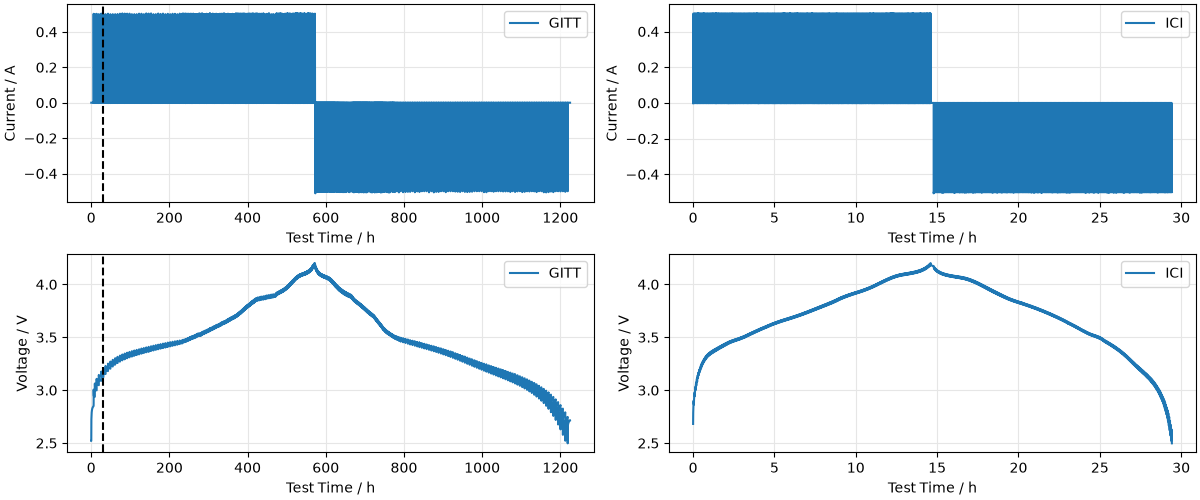

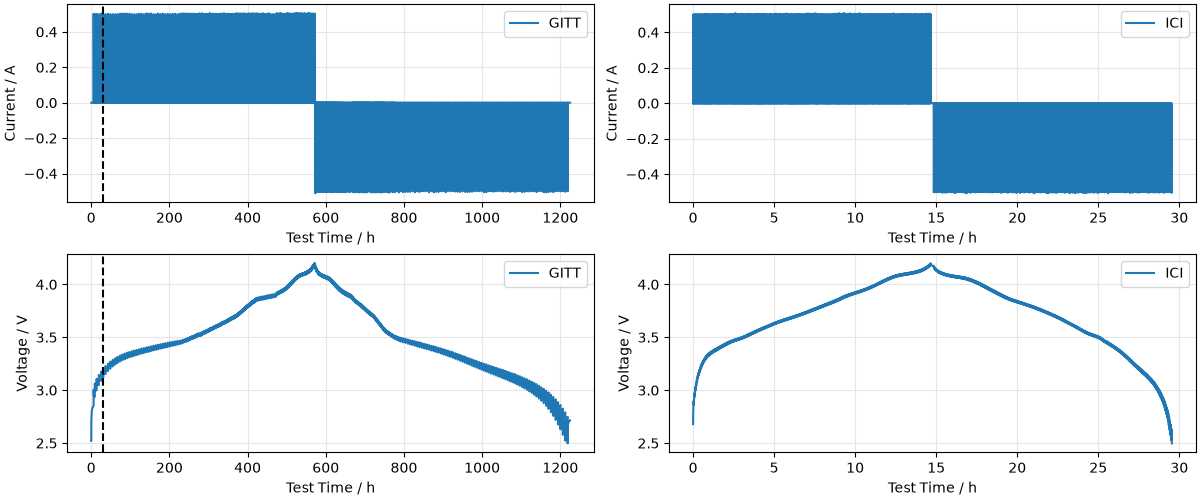

In [4]:
gitt = gitt_parametrization.load_data()
for num,ici in enumerate(ici_parametrization.load_data(),start=1):
    file = ici.select("file").to_series().unique()[0]
    if not file.endswith("001-ici"):
        continue

    fig, axs = plt.subplots(2, 2, figsize=(12, 5), constrained_layout=True)

    axs[0, 0].plot(
        gitt.select("Test Time / h").to_series(),
        gitt.select("Current / A").to_series(),
        label="GITT",
    )

    axs[1, 0].plot(
        gitt.select("Test Time / h").to_series(),
        gitt.select("Voltage / V").to_series(),
        label="GITT",
    )
    axs[0, 1].plot(
        ici.select("Test Time / h").to_series(),
        ici.select("Current / A").to_series(),
        label="ICI",
    )

    axs[1, 1].plot(
        ici.select("Test Time / h").to_series(),
        ici.select("Voltage / V").to_series(),
        label="ICI",
    )
    for ax in axs[0, :]:
        ax.set_ylabel("Current / A")
    for ax in axs[1, :]:
        ax.set_ylabel("Voltage / V")
    for ax in axs[:, 0]:
        ax.axvline(
            x=ici.select("Test Time / h").to_series().max(), color="k", linestyle="--"
        )
    for ax in axs.ravel():
        ax.set_xlabel("Test Time / h")
        ax.grid(True, which="both", axis="both", color="0.9", linestyle="-")
        ax.legend(loc="upper right")
    fig.savefig(f"ici_gitt_comparison_{num}.png", dpi=300, bbox_inches="tight")


In [ ]:
import polars as pl

ici.with_columns(
    (pl.col("Test Time / h").diff() * pl.col("Current / A").shift(1))
    .fill_null(0)
    .cum_sum()
    .over("Direction / 1")
    .alias("Charge / Ah"),
).group_by("Direction / 1").agg(
    pl.col("Charge / Ah").min().alias("Min Charge / Ah"),
    pl.col("Charge / Ah").max().alias("Max Charge / Ah"),
)

Direction / 1,Min Charge / Ah,Max Charge / Ah
str,f64,f64
"""Charge""",-9.9877e-10,4.792856
"""Discharge""",-4.810933,0.0
